# CENG313 Ödev 1: Keşifsel Veri Analizi ve Baseline
**Grup 23:** İbrahim BETBAŞI (23118080058), Koray CİHAN (23118080043)

**Yarışma:** [Eedi - Mining Misconceptions in Mathematics](https://www.kaggle.com/competitions/eedi-mining-misconceptions-in-mathematics)

**İçindekiler**
0. Kurulum
1. Problem tanımı
2. Veriye genel bakış
3. Keşifsel veri analizi
4. Ön işleme
5. Baseline modeller
6. Kaggle gönderimi
7. Sonuç

## 0. Kurulum
Colab'da bu notebook repoyu klonlar ve veriyi Kaggle API ile indirir. Önce Colab'ın **Secrets** paneline `KAGGLE_USERNAME` ve `KAGGLE_KEY` eklenmeli ve Kaggle'da yarışma kuralları kabul edilmelidir. Yerelde çalıştırırken veri `data/` klasöründe aranır.

Tekrar kullanılan kod `src/` içindedir; notebook yalnızca bu fonksiyonları çağırır.

In [1]:
import os
import subprocess
import sys
import zipfile
from pathlib import Path

REPO_URL = "https://github.com/ceng313-2026/GROUP23_CENG313.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    repo_dir = Path("/content") / Path(REPO_URL).stem
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
from src.data import COMPETITION

DATA_DIR = Path(os.environ.get("EEDI_DATA_DIR", ROOT / "data"))

if not (DATA_DIR / "train.csv").exists():
    DATA_DIR.mkdir(exist_ok=True)
    if IN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", str(DATA_DIR)], check=True)
    with zipfile.ZipFile(DATA_DIR / f"{COMPETITION}.zip") as archive:
        archive.extractall(DATA_DIR)

print(sorted(path.name for path in DATA_DIR.iterdir()))

['misconception_mapping.csv', 'sample_submission.csv', 'test.csv', 'train.csv']


In [3]:
import numpy as np
import pandas as pd

from src.data import ANSWER_TEXT_COLUMNS, LONG_COLUMNS, MISCONCEPTION_COLUMNS, OPTIONS, load_misconceptions, load_questions, to_long
from src.models import PopularityBaseline
from src.utils import (
    apply_plot_style,
    candidates_for_share,
    has_image,
    has_latex,
    lexical_overlap,
    misconception_frequency,
    missing_table,
    plot_bars,
    plot_cumulative_share,
    plot_histogram,
    plot_rank_frequency,
    quality_checks,
    rank_correlation,
    repeated_option_mask,
    repeated_question_texts,
    top_k_hit_rate,
    top_share,
    unseen_label_share,
    word_count,
)

apply_plot_style()
pd.set_option("display.max_colwidth", 120)

## 1. Problem tanımı
**Görev:** Eedi platformundaki her çoktan seçmeli matematik sorusunun bir doğru, üç yanlış şıkkı vardır. Öğrencinin yanlış bir şıkkı seçmesinin arkasında genellikle bir **kavram yanılgısı** (misconception) yatar; örneğin "kesirleri toplarken payları ve paydaları ayrı ayrı toplamak". Amaç, her yanlış şık için bu yanılgıyı tahmin etmektir.

**Hedef değişken:** Her yanlış şıkkın `MisconceptionId` değeri. Aday listesi `misconception_mapping.csv` içindeki 2.587 kavram yanılgısıdır. Model her yanlış şık için en olası 25 adayı sıralı olarak verir.

**Girdi:** Soru metni, doğru cevap, yanlış cevap ve soru bağlamı (konu ve construct adı).

**Değerlendirme metriği:** MAP@25 (Mean Average Precision @ 25):

$$\text{MAP@25} = \frac{1}{U}\sum_{u=1}^{U}\sum_{k=1}^{\min(n,25)} P(k)\,\text{rel}(k)$$

Burada $U$ yanlış şık sayısı, $P(k)$ ilk $k$ tahmindeki kesinlik, $\text{rel}(k)$ ise $k$. tahmin doğruysa 1, değilse 0'dır. Her yanlış şıkkın tek bir doğru etiketi olduğu için bu metrik, doğru etiketin sırasının tersinin ($1/\text{sıra}$) ortalamasına eşittir. Doğru etiket ilk 25'te yoksa o satırın puanı 0 olur.

**Problem türü:** 2.587 sınıflı bir sınıflandırma gibi görünse de, aday sayısının çok olması ve bazı adayların eğitimde hiç geçmemesi nedeniyle problem daha çok bir **bilgi erişimi / sıralama** problemidir: sorgu metni, kavram yanılgısı metinleriyle eşleştirilir.

**Veriye başlamadan önce sorduğumuz sorular**
- **Güven:** Etiketler eksiksiz ve tutarlı mı? Hepsi aday listesinde var mı?
- **Uç değerler:** Hangi kavram yanılgıları ve konular baskın? Alışılmadık uzunlukta sorular var mı?
- **Dağılımlar:** Etiketler ne kadar dengesiz? Kaç aday eğitimde hiç geçmiyor?
- **İlişkiler:** Etiketlenme konuya bağlı mı? Sorgu ve doğru kavram yanılgısı ortak kelimeler içeriyor mu?

## 2. Veriye genel bakış
### 2.1 Dosyalar, boyutlar ve veri tipleri

In [4]:
train = load_questions(DATA_DIR, "train")
test = load_questions(DATA_DIR, "test")
misconceptions = load_misconceptions(DATA_DIR)

shapes = pd.DataFrame(
    {name: frame.shape for name, frame in {"train": train, "test": test, "misconceptions": misconceptions}.items()},
    index=["satır (n)", "sütun (m)"],
).T
display(shapes)
display(train.head(3))
display(train.dtypes.to_frame("veri_tipi"))
display(misconceptions.head(3))

,satır (n),sütun (m)
train,1869,15
test,3,11
misconceptions,2587,2


,QuestionId,ConstructId,ConstructName,SubjectId,SubjectName,CorrectAnswer,QuestionText,AnswerAText,AnswerBText,AnswerCText,AnswerDText,MisconceptionAId,MisconceptionBId,MisconceptionCId,MisconceptionDId
0,0,856,Use the order of operations to carry out calculations involving powers,33,BIDMAS,A,\[\n3 \times 2+4-5\n\]\nWhere do the brackets need to go to make the answer equal \( 13 \) ?,\( 3 \times(2+4)-5 \),\( 3 \times 2+(4-5) \),\( 3 \times(2+4-5) \),Does not need brackets,NaN,NaN,NaN,1672.0
1,1,1612,Simplify an algebraic fraction by factorising the numerator,1077,Simplifying Algebraic Fractions,D,"Simplify the following, if possible: \( \frac{m^{2}+2 m-3}{m-3} \)",\( m+1 \),\( m+2 \),\( m-1 \),Does not simplify,2142.0,143.0,2142.0,NaN
2,2,2774,Calculate the range from a list of data,339,Range and Interquartile Range from a List of Data,B,"Tom and Katie are discussing the \( 5 \) plants with these heights:\n\( 24 \mathrm{~cm}, 17 \mathrm{~cm}, 42 \mathrm...",Only\nTom,Only\nKatie,Both Tom and Katie,Neither is correct,1287.0,NaN,1287.0,1073.0


,veri_tipi
QuestionId,int64
ConstructId,int64
ConstructName,object
SubjectId,int64
SubjectName,object
CorrectAnswer,object
QuestionText,object
AnswerAText,object
AnswerBText,object
AnswerCText,object


,MisconceptionId,MisconceptionName
0,0,Does not know that angles in a triangle sum to 180 degrees
1,1,Uses dividing fractions method for multiplying fractions
2,2,Believes there are 100 degrees in a full turn


**Yorum:** Eğitim verisinde 1.869 soru ve 15 sütun var. Her satır bir soru; dört şık metni ve her şık için bir `Misconception*Id` sütunu yan yana duruyor. Açık test dosyası yalnızca 3 sorudan oluşuyor; puanlanan asıl test seti gizli. Aday listesinde 2.587 kavram yanılgısı var.

`Misconception*Id` sütunları kimlik numarası olduğu halde `float64` tipinde. Bunun nedeni eksik değerler: pandas, tamsayı sütununda `NaN` tutabilmek için tipi ondalığa çeviriyor. Ön işlemede bu sütunlar tekrar tamsayıya çevriliyor.

### 2.2 Özet istatistikler

In [5]:
display(train.describe().T.round(1))
display(train.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
QuestionId,1869.0,934.0,539.7,0.0,467.0,934.0,1401.0,1868.0
ConstructId,1869.0,1613.3,1060.6,4.0,575.0,1470.0,2637.0,3526.0
SubjectId,1869.0,225.4,238.5,33.0,92.0,203.0,238.0,1984.0
MisconceptionAId,1135.0,1308.6,744.5,1.0,686.0,1336.0,1954.0,2585.0
MisconceptionBId,1118.0,1308.0,766.5,1.0,628.5,1379.0,1970.0,2586.0
MisconceptionCId,1080.0,1285.3,742.2,2.0,652.2,1294.5,1912.0,2585.0
MisconceptionDId,1037.0,1264.6,759.8,0.0,578.0,1282.0,1897.0,2583.0


,count,unique,top,freq
ConstructName,1869,757,Calculate the square of a number,14
SubjectName,1869,163,Linear Equations,53
CorrectAnswer,1869,4,C,488
QuestionText,1869,1857,Which of the following pairs of function machines are correct?,4
AnswerAText,1869,1219,Only Tom,93
AnswerBText,1869,1230,Only Katie,109
AnswerCText,1869,1222,Both Tom and Katie,158
AnswerDText,1869,1184,Neither is correct,187


**Yorum:**
- **Sayısal sütunlar:** `QuestionId`, `ConstructId`, `SubjectId` ve `Misconception*Id` sayısal görünse de **kimlik numarasıdır**, bu yüzden ortalama ve standart sapmaları bir anlam taşımaz. Asıl bilgi `count` satırında: her `Misconception*Id` sütununda yalnızca 1.037 ile 1.135 arasında değer var, yani yaklaşık 1.869'un %40'ı eksik. Kimlik aralıkları da tutarlı: `QuestionId` 0'dan 1.868'e kadar boşluksuz ilerliyor, etiketler de 0-2.586 aday aralığının içinde kalıyor.
- **Metin sütunları:** 757 farklı construct ve 163 farklı konu var. En sık konu "Linear Equations" (53 soru). 1.869 sorunun 1.857 farklı metni var; birkaç soru metni tekrar ediyor (2.4'te inceleniyor). Şıklarda en sık değerler "Only Tom", "Only Katie", "Both Tom and Katie" ve "Neither is correct". Bunlar, iki öğrencinin iddiasının değerlendirildiği kalıp sorulardan geliyor ve şık metninin tek başına çoğu zaman yeterli bilgi taşımadığını gösteriyor.

### 2.3 Eksik değerler
**Verinin kaynağı:** Sorular ve etiketler, çevrim içi matematik platformu Eedi'den ve yarışmayı düzenleyen ekipten geliyor. Etiketler insan yargısıyla verildiği için etiket gürültüsü içerebilir.

In [6]:
display(missing_table(train))
display(missing_table(misconceptions))

,eksik,yüzde
MisconceptionDId,832,44.52
MisconceptionCId,789,42.22
MisconceptionBId,751,40.18
MisconceptionAId,734,39.27
QuestionId,0,0.00
ConstructId,0,0.00
ConstructName,0,0.00
QuestionText,0,0.00
CorrectAnswer,0,0.00
SubjectName,0,0.00


,eksik,yüzde
MisconceptionId,0,0.0
MisconceptionName,0,0.0


In [7]:
long_all = to_long(train, drop_unlabeled=False, keep_columns=["SubjectId", "SubjectName", "ConstructId", "ConstructName"])

expected_rows = len(train) * (len(OPTIONS) - 1)
assert len(long_all) == expected_rows, "Her soru tam olarak üç yanlış şık satırı üretmeli."

labeled = long_all.dropna(subset=["MisconceptionId"]).copy()
labeled["MisconceptionId"] = labeled["MisconceptionId"].astype("int64")
unlabeled_count = len(long_all) - len(labeled)

print(f"Yanlış şık:  {len(long_all):,}")
print(f"Etiketli:    {len(labeled):,} ({len(labeled) / len(long_all):.1%})")
print(f"Etiketsiz:   {unlabeled_count:,} ({unlabeled_count / len(long_all):.1%})")

Yanlış şık:  5,607
Etiketli:    4,370 (77.9%)
Etiketsiz:   1,237 (22.1%)


**Yorum:** Eksik değerlerin hepsi `Misconception*Id` sütunlarında (%39,3 ile %44,5 arası); metin sütunlarının hiçbirinde eksik yok. Bu eksikliğin bir kısmı **tasarımdan kaynaklanıyor**: doğru şıkkın kavram yanılgısı olmaz, bu da her sütunun yaklaşık dörtte biri demek. Doğru şıklar çıkarıldığında 5.607 yanlış şıktan 1.237'sinin (%22,1) etiketi yok. Bu şıklara hiçbir kavram yanılgısı atanmamış; neden atanmadığı veride belirtilmiyor. Bu satırların nasıl ele alındığı 4. bölümde anlatılıyor.

### 2.4 Tekrarlar ve tutarlılık kontrolleri
Sıfır, kontrolün geçtiği anlamına gelir. Gürültü türleri dersteki sınıflandırmayı izler: tekrar, hatalı, eksik, tutarsız ve çelişkili değerler.

In [8]:
checks = quality_checks(train, misconceptions, long_all)
display(checks)
failed = checks[checks["sayı"] > 0]
print(f"{len(checks)} kontrolden {len(failed)} tanesi sorun buldu.")

,kontrol,gürültü_türü,sayı
0,Tamamen aynı satır,Tekrar,0
1,Tekrarlanan QuestionId,Tekrar,0
2,Daha önce geçen bir QuestionText'i tekrarlayan soru,Tekrar,12
3,Listede tekrarlanan MisconceptionId,Tekrar,0
4,Listede tekrarlanan MisconceptionName,Tekrar,1
5,A-D dışında CorrectAnswer,Hatalı,0
6,Misconception etiketi taşıyan doğru şık,Hatalı,0
7,Listede olmayan etiket,Hatalı,0
8,Soru metni eksik soru,Eksik,0
9,Eksik şık metni,Eksik,0


13 kontrolden 5 tanesi sorun buldu.


Sıfır olmayan bir sayı, satırları silmek için değil, incelemek için bir nedendir:

In [9]:
text_groups = repeated_question_texts(train)
display(text_groups)
print(f"Şıkları da aynı olan tekrar metinler: {int(text_groups['şıklar_aynı'].sum())} / {len(text_groups)}")

repeated_options = train[repeated_option_mask(train)]
option_uses_image = repeated_options[ANSWER_TEXT_COLUMNS].apply(lambda column: has_image(column)).any(axis=1)
print(f"Aynı metinli şıkları olan soru: {len(repeated_options)}, bunlardan şıkları görsel olan: {int(option_uses_image.sum())}")

labels_per_query = labeled.groupby("QueryText")["MisconceptionId"].nunique()
contradictory = labeled[labeled["QueryText"].isin(labels_per_query[labels_per_query > 1].index)]
display(contradictory[["QuestionId", "Answer", "MisconceptionId"]])
print(f"Çelişkili satırlardan görsel açıklaması içeren: {int(has_image(contradictory['QueryText']).sum())} / {len(contradictory)}")

,QuestionText,soru_sayısı,construct_sayısı,şıklar_aynı
0,An isosceles triangle must have ...,2,1,False
1,"By comparing the fraction of the rectangle that is shaded in each diagram, decide which is the odd one out?",2,1,False
2,One of these equations has exactly one solution. Which is it?,2,1,False
3,One of these equations has no real solutions Which is it?,2,1,False
4,One of these equations has no real solutions. Which is it?,2,1,False
5,Which of the following numbers is a cube number?,2,1,False
6,Which of the following pairs of function machines are correct?,4,1,False
7,Which of the numbers is the same when rounded to \( 2 \) decimal places or to \( 2 \) significant figures?,2,1,False
8,Which of these is a cube number?,2,1,False
9,"\( 1,3,6,10,15,21,28 \ldots \) What is the name commonly given to this sequence of numbers?",2,1,False


Şıkları da aynı olan tekrar metinler: 0 / 10
Aynı metinli şıkları olan soru: 7, bunlardan şıkları görsel olan: 6


,QuestionId,Answer,MisconceptionId
540,180,B,1572
541,180,C,1990
542,180,D,1990
2295,765,B,2241
2296,765,C,2025
2297,765,D,1927


Çelişkili satırlardan görsel açıklaması içeren: 6 / 6


**Yorum:**
- **Tam tekrar yok:** Hiçbir satır, `QuestionId` ya da aday kimliği tekrarlanmıyor; doğru şıkkı etiketlenmiş ya da listede olmayan bir etikete sahip satır da yok.
- **Tekrar eden soru metinleri gerçek tekrar değil:** 12 soru, daha önce geçen bir metni kullanıyor. Ancak bu metinler "Which of these is a cube number?" gibi genel kalıplar ve şıkları her seferinde farklı. Bu nedenle hepsi tutuldu.
- **Aynı şıklar ve çelişkili etiketler görsellerden geliyor:** Görseller veride yalnızca alt metin olarak (`![açıklama](...)`) saklanıyor. Farklı görsellerin açıklaması aynı olduğunda, farklı şıklar metinde birebir aynı görünüyor ve aradaki gerçek fark kayboluyor. Aynı metinli şıkları olan 7 sorunun 6'sı ve çelişkili 6 satırın tamamı bu durumdan kaynaklanıyor. Bu satırları silmek sorunu çözmez; bu, metin temsilinin bir sınırı.
- **Aday listesinde bir isim tekrar ediyor:** iki farklı kimlik aynı açıklamayı taşıyor. Bu, iki adayın metinle ayırt edilemeyeceği anlamına geliyor; etkisi küçük.
- **Fazladan boşluklar:** Çoğu metin içindeki satır sonları; geri kalanı metin sonundaki ve ardışık boşluklar. Sorgular oluşturulurken `clean_text` ile düzeltiliyor.

## 3. Keşifsel veri analizi
### 3.1 Hedef dengesi: kavram yanılgılarının sıklığı
Görevin en önemli dağılımı budur. Dağılımın uzun kuyruklu olması, adayların çoğunun yalnızca sıklıkla sıralanamayacağı anlamına gelir.

,değer
listedeki aday,2587.000
train'de kullanılan,1604.000
train'de hiç kullanılmayan,983.000
yalnızca bir kez kullanılan,747.000
medyan kullanım (kullanılanlar),2.000
en fazla kullanım,54.000
en sık 25'in etiket payı,0.136
en sık 100'ün etiket payı,0.297
etiketlerin yarısı için gereken aday,279.000


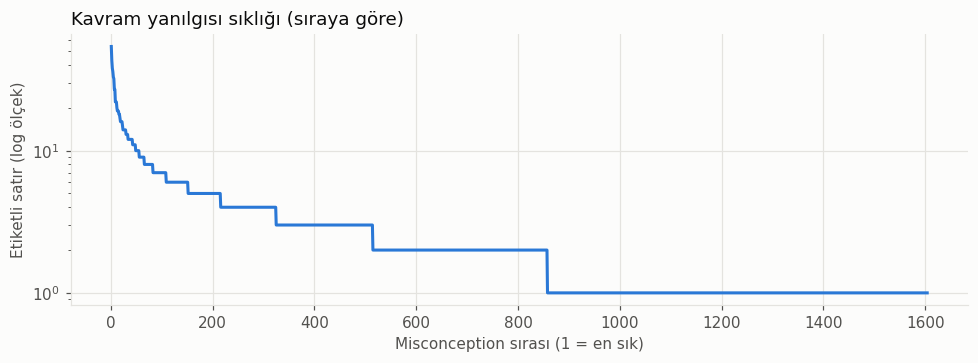

In [10]:
frequency = misconception_frequency(labeled, misconceptions)
counts = frequency["kullanım"]
used = counts[counts > 0]

frequency_stats = pd.Series(
    {
        "listedeki aday": len(frequency),
        "train'de kullanılan": int((counts > 0).sum()),
        "train'de hiç kullanılmayan": int((counts == 0).sum()),
        "yalnızca bir kez kullanılan": int((counts == 1).sum()),
        "medyan kullanım (kullanılanlar)": float(used.median()),
        "en fazla kullanım": int(counts.max()),
        "en sık 25'in etiket payı": round(top_share(counts, 25), 3),
        "en sık 100'ün etiket payı": round(top_share(counts, 100), 3),
        "etiketlerin yarısı için gereken aday": candidates_for_share(counts, 0.5),
    }
)
display(frequency_stats.to_frame("değer"))
plot_rank_frequency(counts, "Kavram yanılgısı sıklığı (sıraya göre)");

**Yorum:** Dağılım çok dengesiz ve uzun kuyruklu. En sık kavram yanılgısı 54 kez geçiyor, ama bu bile 4.370 etiketin yalnızca %1,2'si. Kullanılan 1.604 adayın medyanı 2 kullanım; 747'si yalnızca bir kez görülüyor. Logaritmik eksende eğri birkaç adımda 1'e iniyor ve uzun bir düz kuyrukla devam ediyor. Ayrıca 983 aday (%38,0) eğitimde **hiç** geçmiyor. Yani modelin bu adaylar için öğrenebileceği tek bilgi, adayın kendi metni.

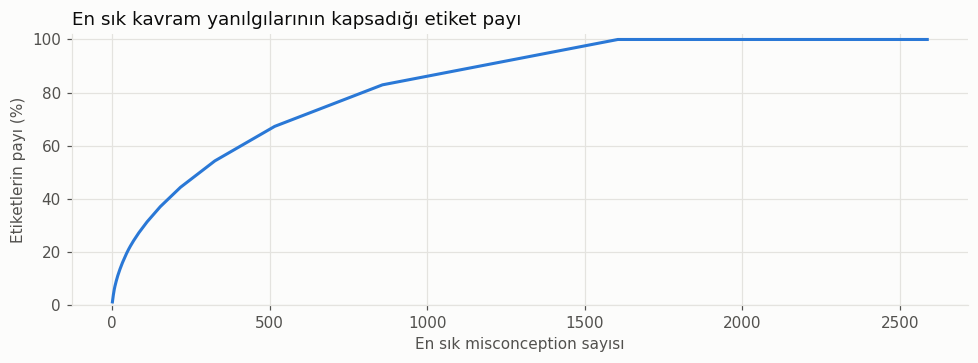

In [11]:
plot_cumulative_share(counts, "En sık kavram yanılgılarının kapsadığı etiket payı");

**Yorum:** En sık 25 kavram yanılgısı etiketlerin yalnızca %13,6'sını, en sık 100'ü %29,7'sini kapsıyor. Etiketlerin yarısına ulaşmak için 279 aday gerekiyor. MAP@25 her satır için sadece 25 tahmine izin verdiği için, herkese aynı listeyi veren sıklık tabanlı bir model en fazla %13,6'lık bir kesime ulaşabilir. İyi bir model tahminlerini soruya göre değiştirmek zorunda.

### 3.2 Yeni sorularda görülmemiş kavram yanılgıları
Sorular bütün olarak, tekrar tekrar ayrılıyor ve ayrılan soruların etiketlerinden kaçının kalan eğitim verisinde hiç geçmediği ölçülüyor. Satır düzeyinde rastgele bölme bunu gizlerdi, çünkü aynı sorunun şıkları iki tarafa da düşerdi.

In [12]:
unseen_shares = unseen_label_share(labeled)
display(unseen_shares.describe().round(3).to_frame())

,görülmemiş_oranı
count,20.000
mean,0.262
std,0.018
min,0.211
25%,0.259
50%,0.265
75%,0.269
max,0.285


**Yorum:** Soruların %20'si ayrıldığında, ayrılan etiketlerin ortalama %26,2'si (20 tekrarda %21,1 ile %28,5 arası) kalan eğitim verisinde hiç yok. Gizli test setinde de benzer bir oran beklenir. Yalnızca eğitimde gördüğü sınıfları tahmin edebilen bir model, bu etiketlerin hiçbirini bulamaz. Doğrulamada bu yüzden **`QuestionId`'ye göre gruplu bölme** kullanılmalı ve skorlar görülen ve görülmeyen kavram yanılgıları için ayrı raporlanmalı.

### 3.3 Soru başına etiket sayısı

,soru payı
1 etiket,0.164
2 etiket,0.333
3 etiket,0.502


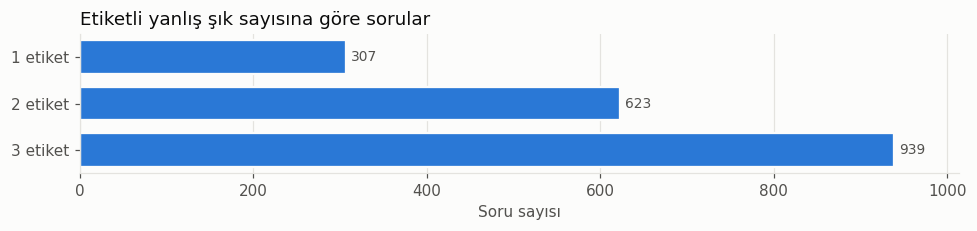

In [13]:
labels_per_question = train[MISCONCEPTION_COLUMNS].notna().sum(axis=1)
label_distribution = labels_per_question.value_counts().sort_index()
label_distribution.index = [f"{count} etiket" for count in label_distribution.index]
display((label_distribution / len(train)).round(3).to_frame("soru payı"))
plot_bars(label_distribution, "Etiketli yanlış şık sayısına göre sorular", "Soru sayısı");

**Yorum:** Soruların yarısında (%50,2) üç yanlış şıkkın üçü de etiketli; %33,3'ünde iki, %16,4'ünde ise yalnızca bir şık etiketli. Hiç etiketi olmayan soru yok. Bu da etiket eksikliğinin, soruların tümden dışarıda kalmasından değil, tek tek şıklardan kaynaklandığını gösteriyor.

### 3.4 Doğru cevabın konumu

,pay
CorrectAnswer,
A,0.258
B,0.247
C,0.261
D,0.234


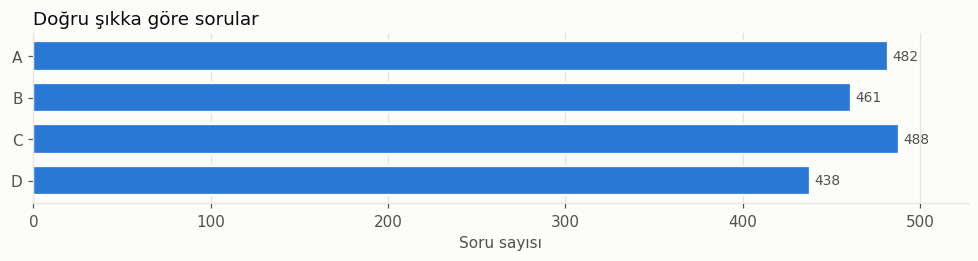

In [14]:
correct_counts = train["CorrectAnswer"].value_counts().reindex(list(OPTIONS)).fillna(0).astype(int)
display((correct_counts / len(train)).round(3).to_frame("pay"))
plot_bars(correct_counts, "Doğru şıkka göre sorular", "Soru sayısı");

**Yorum:** Doğru cevap dört şıkka neredeyse eşit dağılmış (%23,4 ile %26,1 arası). Doğru şıkkın harfi bir ipucu taşımıyor; modelin şık harfinden bir şey öğrenmesi beklenmez. Bu yüzden şık harfi modele girdi olarak verilmiyor.

### 3.5 Konu ve construct dağılımı

,farklı,medyan_soru,en_fazla_soru,tek_sorulu
SubjectName,163,9.0,53,15
ConstructName,757,2.0,14,302


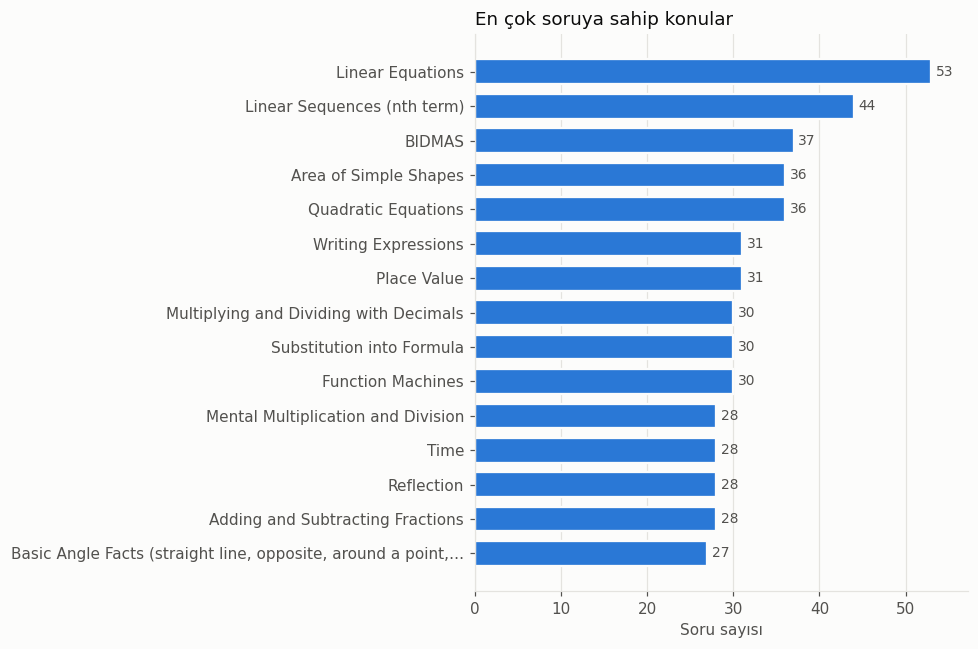

In [15]:
subject_counts = train["SubjectName"].value_counts()
construct_counts = train["ConstructName"].value_counts()

summary = pd.DataFrame(
    {
        "farklı": [subject_counts.size, construct_counts.size],
        "medyan_soru": [subject_counts.median(), construct_counts.median()],
        "en_fazla_soru": [subject_counts.max(), construct_counts.max()],
        "tek_sorulu": [(subject_counts == 1).sum(), (construct_counts == 1).sum()],
    },
    index=["SubjectName", "ConstructName"],
)
display(summary)
plot_bars(subject_counts.head(15), "En çok soruya sahip konular", "Soru sayısı");

**Yorum:** 163 konu ve 757 construct var. Konular dengeli değil: en büyük konu "Linear Equations" 53 soruya sahipken, medyan konu 9 soru içeriyor ve 15 konunun yalnızca bir sorusu var. Construct'lar daha da parçalı: medyan construct 2 soru içeriyor ve 302 construct yalnızca bir soruda geçiyor. Veri, çok sayıda küçük gruptan oluşuyor; bu yüzden her konu için ayrı model kurmak yerine, tüm adayları tek bir ortak model ile sıralamak daha uygun.

### 3.6 Uç değerler

,MisconceptionId,MisconceptionName,kullanım
0,1214,"When solving an equation, uses the same operation rather than the inverse.",54
1,1379,Rounds down instead of up,43
2,2316,Mixes up squaring and multiplying by 2 or doubling,38
3,1507,Carries out operations from left to right regardless of priority order,36
4,1990,Fails to reflect across mirror line,33
5,1880,Mixes up greater than and less than symbols,32
6,1597,Believes multiplying two negatives gives a negative answer,27
7,2392,Rounds to the wrong degree of accuracy (rounds too much),27
8,77,"Does not follow the arrows through a function machine, changes the order of the operations asked.",22
9,220,Only multiplies the first term in the expansion of a bracket,22


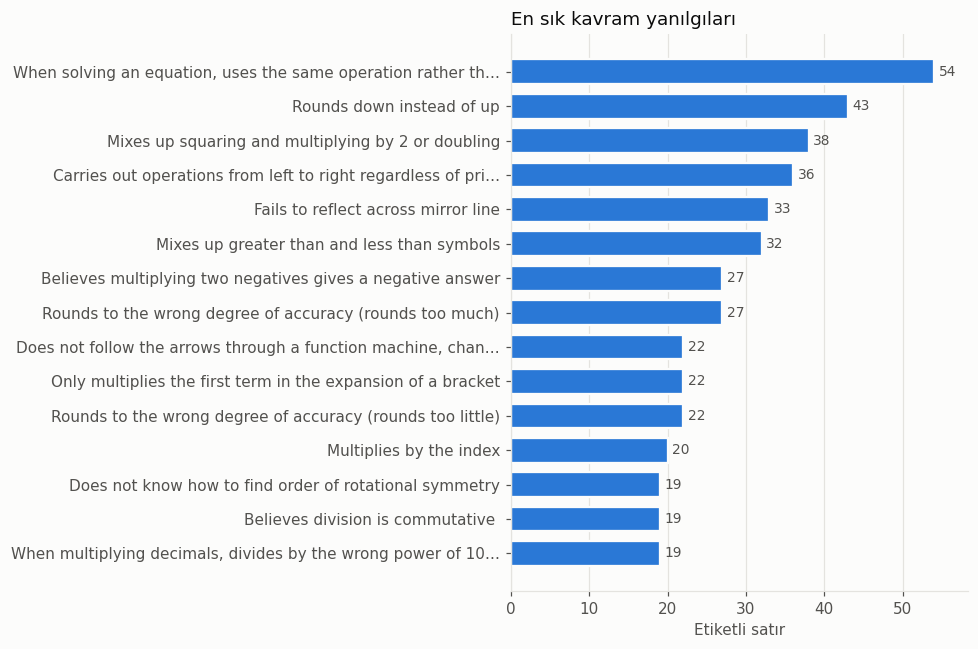

In [16]:
display(frequency.head(10)[["MisconceptionId", "MisconceptionName", "kullanım"]])
top_names = frequency.head(15).set_index("MisconceptionName")["kullanım"]
plot_bars(top_names, "En sık kavram yanılgıları", "Etiketli satır");

**Yorum:** En sık kavram yanılgıları temel işlem hataları: denklem çözerken ters işlem yerine aynı işlemi uygulamak (54), yukarı yuvarlamak yerine aşağı yuvarlamak (43) ve kare almayı 2 ile çarpmakla karıştırmak (38). Listede birbirinin tersi olan çiftler de var: "yukarı yerine aşağı yuvarlar" ve "aşağı yerine yukarı yuvarlar" gibi. Bu çiftler metin olarak çok benzer ama anlamca zıt; kelime tabanlı bir modelin bunları karıştırması muhtemel.

In [17]:
question_words = word_count(train["QuestionText"])
question_has_image = has_image(train["QuestionText"])
extremes = train.assign(kelime=question_words)[["QuestionId", "SubjectName", "kelime", "QuestionText"]]
print("En uzun sorular")
display(extremes.nlargest(3, "kelime"))
print("En kısa sorular")
display(extremes.nsmallest(3, "kelime"))
print(f"Medyan kelime: görselli sorular {question_words[question_has_image].median():g}, görselsiz sorular {question_words[~question_has_image].median():g}")
long_questions = question_words > question_words.quantile(0.95)
print(f"En uzun %5'lik dilimdeki {int(long_questions.sum())} sorunun {question_has_image[long_questions].mean():.1%}'i görsel içeriyor")

En uzun sorular


,QuestionId,SubjectName,kelime,QuestionText
939,939,Linear Sequences (nth term),236,Tom and Katie are discussing this sequence. ![The first 3 patterns in a sequence are shown. The first pattern is a b...
790,790,Reflection,235,"![A grid of 8 squares across and 7 squares up. A blue isosceles triangle, labelled ""P"", is drawn on the grid. Its c..."
367,367,Reflection,190,"![A grid of 7 squares across and 7 squares up. A red vertical line goes from the bottom to the top of the grid, it i..."


En kısa sorular


,QuestionId,SubjectName,kelime,QuestionText
39,39,Place Value,3,\( 598-1000= \)
193,193,Laws of Indices,3,\( (27)^{\frac{4}{3}}=? \)
241,241,"Square Roots, Cube Roots, etc",3,\( \sqrt{-16}=? \)


Medyan kelime: görselli sorular 43, görselsiz sorular 15
En uzun %5'lik dilimdeki 91 sorunun 90.1%'i görsel içeriyor


**Yorum:** En uzun sorular, uzun görsel açıklamaları (`![...]`) içeren sorular; en kısaları ise `\( 598-1000= \)` gibi tek satırlık işlemler. Görselli soruların medyanı 43 kelime, görselsizlerin 15 kelime. En uzun %5'lik dilimdeki soruların %90,1'i görsel içeriyor. Uzunluktaki uç değerler hata değil, sorunun biçiminden kaynaklanıyor; bu yüzden çıkarılmadı.

### 3.7 Metin özellikleri
Metin uzunlukları, metin tabanlı modellerde token sınırının seçimine yön verir. LaTeX ve görsel oranları ise düz kelime tabanlı bir temsilin ne kadar içeriği yanlış okuyabileceğini ya da kaybedebileceğini gösterir.

,count,mean,std,min,50%,95%,max,latex_payı,görsel_payı
QuestionText,1869.0,30.3,25.9,3.0,22.0,81.0,236.0,0.795,0.338
Şık metinleri,7476.0,4.7,7.6,1.0,3.0,10.0,127.0,0.745,0.040
MisconceptionName,2587.0,12.1,5.2,2.0,11.0,22.0,35.0,0.000,0.000
QueryText,4370.0,43.7,28.3,14.0,36.0,98.0,269.0,0.924,0.374


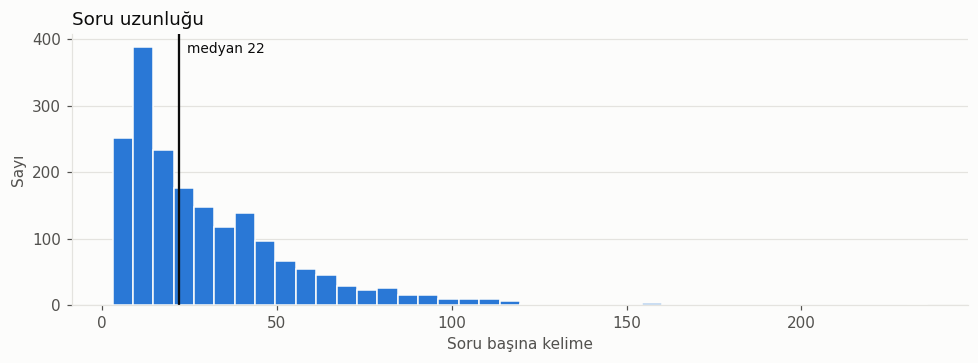

In [18]:
answer_text = train[ANSWER_TEXT_COLUMNS].stack()
text_fields = {
    "QuestionText": train["QuestionText"],
    "Şık metinleri": answer_text,
    "MisconceptionName": misconceptions["MisconceptionName"],
    "QueryText": labeled["QueryText"],
}
text_summary = pd.DataFrame(
    {
        name: {
            **word_count(values).describe(percentiles=[0.5, 0.95]).round(1).to_dict(),
            "latex_payı": round(float(has_latex(values).mean()), 3),
            "görsel_payı": round(float(has_image(values).mean()), 3),
        }
        for name, values in text_fields.items()
    }
).T
display(text_summary)
plot_histogram(question_words, "Soru uzunluğu", "Soru başına kelime");

**Yorum:** Soru uzunluğu sağa çarpık: medyan 22 kelime, soruların %95'i 81 kelimenin altında, en uzun soru ise 236 kelime. Soruların %79,5'i LaTeX, %33,8'i görsel içeriyor. Sorgu metni (soru, doğru cevap ve yanlış cevap birlikte) medyan 36 kelime; sorguların %95'i 98 kelimenin altında, en uzunu 269 kelime. Sık kullanılan küçük cümle gömme modelleri yaklaşık 256 token ile sınırlı ve LaTeX ifadeleri çok sayıda tokena bölünüyor. Bu yüzden sorguların çoğu bu sınıra sığsa da en uzun sorguların sonu kesilebilir.

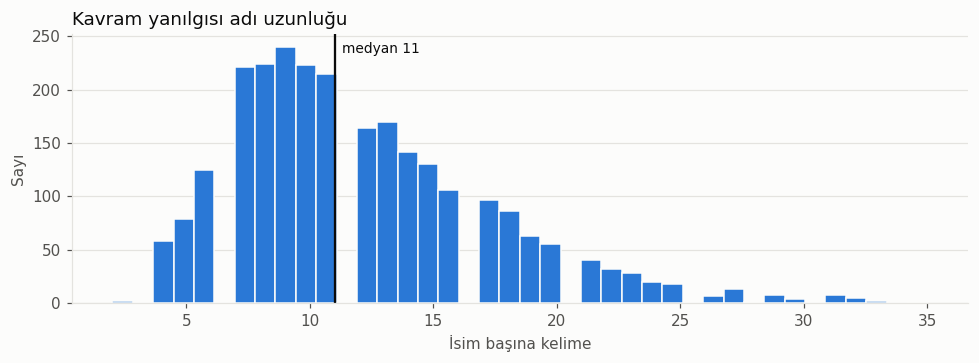

In [19]:
plot_histogram(word_count(misconceptions["MisconceptionName"]), "Kavram yanılgısı adı uzunluğu", "İsim başına kelime");

**Yorum:** Kavram yanılgısı isimleri kısa ve düzenli: medyan 11, en fazla 35 kelime. Hiçbirinde LaTeX yok. Matematik, sorgu tarafında LaTeX ile (`\frac`, `\times`), isim tarafında ise düz İngilizce ile ("multiplies", "fractions") yazılmış. Bu dil farkı, iki metin arasındaki kelime eşleşmesini zorlaştırıyor (3.8.5).

### 3.8 Hedefle ilişkiler
#### 3.8.1 Etiketsiz şık oranı konuya bağlı mı?

In [20]:
subject_rates = long_all.groupby("SubjectName")["MisconceptionId"].agg(satır="size", etiketli="count")
subject_rates["etiketsiz_payı"] = 1 - subject_rates["etiketli"] / subject_rates["satır"]
frequent_subjects = subject_rates[subject_rates["satır"] >= 30].sort_values("etiketsiz_payı", ascending=False)

display(frequent_subjects.head(10).round(3))
display(frequent_subjects["etiketsiz_payı"].describe().round(3).to_frame())

,satır,etiketli,etiketsiz_payı
SubjectName,,,
Plotting Lines from Tables of Values,51,26,0.49
Multiplying and Dividing Negative Numbers,48,27,0.438
Plotting Quadratics from Tables of Values,42,25,0.405
Simultaneous Equations,66,40,0.394
Probability of Single Events,42,26,0.381
Factorising into a Single Bracket,39,25,0.359
Ordering Fractions,39,25,0.359
Real Life Graphs,75,49,0.347
Mental Multiplication and Division,84,55,0.345


,etiketsiz_payı
count,76.0
mean,0.216
std,0.099
min,0.021
25%,0.138
50%,0.208
75%,0.287
max,0.49


**Yorum:** En az 30 yanlış şıkkı olan 76 konuda etiketsiz şık oranı %2,1 ile %49 arasında değişiyor (ortalama %21,6). Örneğin "Plotting Lines from Tables of Values" konusundaki şıkların yaklaşık yarısı etiketsiz. Eksiklik rastgele değil, konuya bağlı. Bu konular eğitimde daha az temsil edildiği için model bu konularda daha zayıf kalabilir.

#### 3.8.2 Aynı sorunun şıkları aynı kavram yanılgısını paylaşıyor mu?

In [21]:
per_question = labeled.groupby("QuestionId")["MisconceptionId"].agg(etiket="size", farklı="nunique")
multiple = per_question[per_question["etiket"] >= 2]
shared_share = float((multiple["farklı"] < multiple["etiket"]).mean())
print(f"En az iki etiketli soru: {len(multiple):,}")
print(f"...bunlardan aynı kavram yanılgısı tekrar eden: {shared_share:.1%}")

En az iki etiketli soru: 1,562
...bunlardan aynı kavram yanılgısı tekrar eden: 31.5%


**Yorum:** En az iki etiketli 1.562 sorunun %31,5'inde aynı kavram yanılgısı iki şıkta tekrar ediyor. Yani aynı sorunun farklı yanlış cevapları aynı düşünce hatasından gelebiliyor. Bu nedenle bir sorunun şıkları birbirinden bağımsız örnekler sayılmamalı; doğrulamada aynı sorunun şıkları aynı tarafta tutulmalı.

#### 3.8.3 Bir kavram yanılgısı tek bir construct'a mı bağlı?

In [22]:
label_counts = labeled["MisconceptionId"].value_counts()
repeated_labels = labeled[labeled["MisconceptionId"].isin(label_counts[label_counts >= 2].index)]
constructs_per_label = repeated_labels.groupby("MisconceptionId")["ConstructId"].nunique()
subjects_per_label = repeated_labels.groupby("MisconceptionId")["SubjectId"].nunique()
tied = pd.Series(
    {
        "en az iki kez geçen kavram yanılgısı": len(constructs_per_label),
        "yalnızca tek construct'ta geçenlerin payı": round(float((constructs_per_label == 1).mean()), 3),
        "yalnızca tek konuda geçenlerin payı": round(float((subjects_per_label == 1).mean()), 3),
    }
)
display(tied.to_frame("değer"))

,değer
en az iki kez geçen kavram yanılgısı,857.000
yalnızca tek construct'ta geçenlerin payı,0.425
yalnızca tek konuda geçenlerin payı,0.593


**Yorum:** Yalnızca bir kez geçen kavram yanılgıları doğal olarak tek bir construct'ta göründüğü için hesaba katılmadı. En az iki kez geçen 857 kavram yanılgısının %42,5'i tek bir construct'ta, %59,3'ü tek bir konuda kalıyor. Yani kavram yanılgılarının önemli bir kısmı konuya bağlı, ama çoğu birden fazla construct'ta ortaya çıkıyor. Konu ve construct bilgisi yararlı bir ipucu, ancak aday listesini kesin olarak daraltmak için tek başına yeterli değil.

#### 3.8.4 Soru uzunluğu etiket sayısıyla ilişkili mi?

In [23]:
length_label_correlation = rank_correlation(question_words, labels_per_question)
print(f"Spearman korelasyonu: {length_label_correlation:.3f}")

Spearman korelasyonu: -0.110


**Yorum:** Soru uzunluğu ile etiketli şık sayısı arasındaki Spearman korelasyonu -0,110. Uzun soruların biraz daha az etiketi var, ama bu ilişki çok zayıf ve pratikte önemsiz. Uzunluk, etiketlenme sürecini açıklayan bir değişken değil.

#### 3.8.5 Sorgu ve kavram yanılgısı ortak kelimeler içeriyor mu?
Her sorgu hem gerçek kavram yanılgısıyla hem de rastgele atanmış bir kavram yanılgısıyla karşılaştırılıyor. İkisi arasındaki fark, düz kelime eşleştirmenin ne kadar sinyal taşıdığını gösteriyor.

,gerçek_çift,karıştırılmış_çift
count,4370.0000,4370.0000
mean,0.0808,0.0389
std,0.0692,0.0364
min,0.0000,0.0000
25%,0.0312,0.0000
50%,0.0702,0.0357
75%,0.1176,0.0606
max,0.5000,0.2727


Gerçek ismiyle hiç ortak kelimesi olmayan sorgular: 19.5%


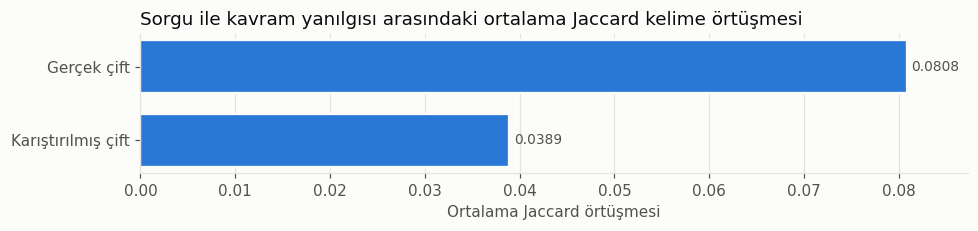

In [24]:
labeled_named = labeled.merge(misconceptions, on="MisconceptionId", how="left", validate="many_to_one")
overlap = lexical_overlap(labeled_named["QueryText"].tolist(), labeled_named["MisconceptionName"].tolist())
display(overlap.describe().round(4))
print(f"Gerçek ismiyle hiç ortak kelimesi olmayan sorgular: {(overlap['gerçek_çift'] == 0).mean():.1%}")
plot_bars(
    overlap.mean().rename({"gerçek_çift": "Gerçek çift", "karıştırılmış_çift": "Karıştırılmış çift"}),
    "Sorgu ile kavram yanılgısı arasındaki ortalama Jaccard kelime örtüşmesi",
    "Ortalama Jaccard örtüşmesi",
);

**Yorum:** Gerçek çiftler, karıştırılmış çiftlerin yaklaşık iki katı kadar ortak kelime içeriyor (0,081'e karşı 0,039). Yani kelime eşleştirmenin gerçek bir sinyali var ve TF-IDF gibi bir baseline'ın rastgeleden iyi olması beklenir. Ancak örtüşme mutlak olarak küçük ve sorguların %19,5'i gerçek kavram yanılgısıyla hiçbir kelimeyi paylaşmıyor. Bu, kelimeler yerine anlamı yakalayan modellere (cümle gömmeleri gibi) yer olduğunu gösteriyor.

### 3.9 Train ve test kapsamı

In [25]:
coverage = pd.Series(
    {
        "test sorusu": len(test),
        "konusu train'de de olan": int(test["SubjectId"].isin(train["SubjectId"]).sum()),
        "construct'ı train'de de olan": int(test["ConstructId"].isin(train["ConstructId"]).sum()),
    }
)
display(coverage.to_frame("değer"))

,değer
test sorusu,3
konusu train'de de olan,3
construct'ı train'de de olan,3


**Yorum:** Açık test dosyasındaki 3 sorunun hepsinin konusu ve construct'ı eğitimde de geçiyor. Gizli test seti çok daha büyük olduğu için bu kontrol yalnızca dosya formatını doğruluyor; gerçek kapsam hakkında bir şey söylemiyor.

## 4. Ön işleme
### 4.1 Tahmin birimine dönüştürme ve birleştirme
Ham tabloda her satır bir soru, ama tahmin birimi yanlış şık. `to_long` her soruyu üç yanlış şık satırına çeviriyor ve her satır için soru, doğru cevap ve yanlış cevabı tek bir `QueryText` metninde birleştiriyor. Ardından kavram yanılgısı isimleri birleştiriliyor. Dersteki gibi, birleştirmeden önce ve sonra satır sayısı kontrol ediliyor.

In [26]:
rows_before = len(labeled)
assert len(labeled_named) == rows_before, "Birleştirme satır sayısını değiştirmemeli."
print(f"Birleştirme öncesi satır: {rows_before:,}; sonrası: {len(labeled_named):,}")
print(f"Eşleşen ismi olmayan satır: {labeled_named['MisconceptionName'].isna().sum():,}")

example = labeled_named.iloc[0]
print()
print(example["QueryText"])
print("Etiket:", example["MisconceptionName"])

model_data = labeled[LONG_COLUMNS]
print()
print(f"Modellere giden tablo: {model_data.shape[0]:,} satır, sütunlar {list(model_data.columns)}")

Birleştirme öncesi satır: 4,370; sonrası: 4,370
Eşleşen ismi olmayan satır: 0

Question: \[ 3 \times 2+4-5 \] Where do the brackets need to go to make the answer equal \( 13 \) ?
Correct answer: \( 3 \times(2+4)-5 \)
Incorrect answer: Does not need brackets
Etiket: Confuses the order of operations, believes addition comes before multiplication 

Modellere giden tablo: 4,370 satır, sütunlar ['QuestionId', 'Answer', 'QueryText', 'MisconceptionId']


### 4.2 Ön işleme kararları ve nedenleri
| Sorun | Karar | Neden |
|---|---|---|
| Soru başına bir satır | Yanlış şık başına bir satıra çevrildi | Tahmin ve değerlendirme birimi yanlış şık |
| Doğru şıklar | Çıkarıldı | Doğru cevabın kavram yanılgısı olmaz; etiketleri de tasarım gereği boş |
| Etiketsiz yanlış şıklar (1.237, %22,1) | Eğitim ve değerlendirmeden çıkarıldı | Bir kimlik numarasının ortalaması ya da modu anlamsız; tahminle doldurulan etiket gürültü olur |
| `float` tipindeki etiketler | Tamsayıya çevrildi | `NaN` yüzünden ondalık görünen değerler aslında kimlik numarası |
| Fazladan boşluk ve satır sonları | `clean_text` ile normalize edildi | Aynı metnin farklı yazımları farklı sayılmasın |
| Tekrar eden soru metinleri (12) | Tutuldu | Şıkları farklı; gerçek tekrar değil |
| Aynı görünen şıklar ve çelişkili etiketler | Tutuldu | Farklılık görselde; satırı silmek bilgiyi geri getirmez |
| LaTeX | Olduğu gibi bırakıldı | Matematiksel anlam taşıyor; nasıl işleneceği modelin metin temsiline bırakıldı |
| Uzun sorular | Tutuldu | Uzunluk çoğunlukla görsel açıklamalarından geliyor, hata değil |
| Kodlama (encoding) ve ölçekleme | Uygulanmadı | Girdi metin, sayısal özellik yok. Kimlikler büyüklük taşımayan kategorik etiketler. Metnin sayısala çevrilmesi (TF-IDF, gömme) modelin bir parçası olarak 5. bölümde yapılıyor |

## 5. Baseline modeller
### 5.1 Popülerlik baseline'ı
Bu model, soru metnine hiç bakmadan her yanlış şık için eğitimdeki en sık 25 kavram yanılgısını tahmin eder. Metin kullanan her modelin geçmesi gereken alt sınırı belirler.

In [27]:
popularity = PopularityBaseline(k=25).fit(labeled)
popularity_predictions = popularity.predict(labeled)

popularity_hit_rate = top_k_hit_rate(labeled["MisconceptionId"], popularity_predictions)
print(f"Eğitim verisinde doğru etiketin ilk 25'te bulunma oranı: {popularity_hit_rate:.1%}")

names = misconceptions.set_index("MisconceptionId")["MisconceptionName"]
display(names.reindex(popularity.top_ids_).reset_index())

Eğitim verisinde doğru etiketin ilk 25'te bulunma oranı: 13.6%


,MisconceptionId,MisconceptionName
0,1214,"When solving an equation, uses the same operation rather than the inverse."
1,1379,Rounds down instead of up
2,2316,Mixes up squaring and multiplying by 2 or doubling
3,1507,Carries out operations from left to right regardless of priority order
4,1990,Fails to reflect across mirror line
5,1880,Mixes up greater than and less than symbols
6,1597,Believes multiplying two negatives gives a negative answer
7,2392,Rounds to the wrong degree of accuracy (rounds too much)
8,77,"Does not follow the arrows through a function machine, changes the order of the operations asked."
9,220,Only multiplies the first term in the expansion of a bracket


**Yorum:** Model, eğitildiği verinin kendisinde bile doğru etiketi satırların yalnızca %13,6'sında ilk 25'e koyabiliyor. Bu bir üst sınır, çünkü aynı veride eğitilip değerlendirildi; yeni sorularda skor daha düşük olacak. Görülmemiş kavram yanılgılarının hiçbirini tahmin edemez, çünkü listesi tamamen eğitimdeki sıklıklardan oluşuyor. MAP@25 doğrulama skoru 5.2'deki karşılaştırmada veriliyor.

### 5.2 Metin tabanlı baseline'lar ve doğrulama
**Doğrulama tasarımı:** Soruların %20'si `QuestionId`'ye göre bütün olarak ayrılıyor (`random_state=42`). Böylece bir sorunun şıkları hem eğitimde hem doğrulamada yer almaz ve doğrulama, gizli test setindeki yeni soruları taklit eder. Skor, yarışmanın metriği **MAP@25** ile hesaplanıyor ve doğru etiketin eğitim kısmında görülüp görülmemesine göre ayrıca raporlanıyor.

In [ ]:
import matplotlib.pyplot as plt
from src.models import EmbeddingCosineBaseline, TfidfCosineBaseline
from src.utils import evaluate_predictions, make_group_kfold_splits, make_holdout_split, write_submission

train_part, val_part = make_holdout_split(model_data, test_size=0.2, random_state=42)
assert not set(train_part["QuestionId"]) & set(val_part["QuestionId"]), "Bir soru iki tarafta birden olmamalı."

seen_in_train = val_part["MisconceptionId"].isin(set(train_part["MisconceptionId"]))
print(f"Eğitim:     {train_part['QuestionId'].nunique():,} soru, {len(train_part):,} satır")
print(f"Doğrulama:  {val_part['QuestionId'].nunique():,} soru, {len(val_part):,} satır")
print(f"Doğrulamada görülen etiket: {seen_in_train.sum():,} (%{seen_in_train.mean() * 100:.1f}), görülmeyen: {(~seen_in_train).sum():,}")

**Modeller:**
- **Popülerlik:** 5.1'deki model, bu kez yalnızca eğitim kısmıyla kuruluyor.
- **TF-IDF + kosinüs:** Sorgu metni ve 2.587 kavram yanılgısı adı TF-IDF vektörlerine çevrilip kosinüs benzerliğine göre sıralanıyor. Matematikte önemli olduğu için tek karakterli token'lar (`x`, `2`, `%`) korunuyor.
- **Cümle gömmesi + kosinüs:** Hazır `all-MiniLM-L6-v2` modeliyle sorgu ve adaylar anlam vektörlerine çevrilip aynı şekilde sıralanıyor. Model ince ayar yapılmadan kullanılıyor.

İki metin modeli etiketlerden öğrenmiyor; tüm aday listesini sıraladıkları için eğitimde hiç geçmeyen kavram yanılgılarını da bulabilirler.

In [ ]:
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
SCORE_COLUMNS = ["MAP@25 (Overall)", "MAP@25 (Seen)", "MAP@25 (Unseen)"]

models = {
    "Popülerlik": PopularityBaseline(k=25).fit(train_part),
    "TF-IDF + kosinüs": TfidfCosineBaseline(k=25).fit(misconceptions, train_part),
    "Cümle gömmesi + kosinüs": EmbeddingCosineBaseline(EMBEDDING_MODEL, k=25).fit(misconceptions),
}
val_predictions = {name: model.predict(val_part) for name, model in models.items()}

results = pd.DataFrame(
    {name: evaluate_predictions(train_part, val_part, preds) for name, preds in val_predictions.items()}
).T
results["İlk 25'te bulma"] = [top_k_hit_rate(val_part["MisconceptionId"], preds) for preds in val_predictions.values()]
display(results[[*SCORE_COLUMNS, "İlk 25'te bulma"]].astype(float).round(4))

In [ ]:
labels_tr = {"MAP@25 (Overall)": "Genel", "MAP@25 (Seen)": "Görülen", "MAP@25 (Unseen)": "Görülmeyen"}
ax = results[SCORE_COLUMNS].astype(float).rename(columns=labels_tr).plot.bar(figsize=(9, 3.6), rot=0, width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
ax.set_ylabel("MAP@25")
ax.set_xlabel("")
ax.set_title("Doğrulama MAP@25: genel, görülen ve görülmeyen kavram yanılgıları")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Yorum:** _Notebook çalıştırıldıktan sonra çıkan skorlara göre yazılacak._

#### 5.2.1 Beş katlı gruplu çapraz doğrulama
Tek bir %20'lik ayrımın skoru şansa bağlı olabilir. Aynı modeller `GroupKFold` ile beş farklı ayrımda değerlendirilip ortalama ve standart sapma veriliyor. Gömme modeli eğitim verisine bağlı olmadığı için adaylar bir kez kodlanıyor.

In [ ]:
embedding_model = models["Cümle gömmesi + kosinüs"]
cv_rows = []
for fold, (fold_train, fold_val) in enumerate(make_group_kfold_splits(model_data, n_splits=5), start=1):
    fold_models = {
        "Popülerlik": PopularityBaseline(k=25).fit(fold_train),
        "TF-IDF + kosinüs": TfidfCosineBaseline(k=25).fit(misconceptions, fold_train),
        "Cümle gömmesi + kosinüs": embedding_model,
    }
    for name, model in fold_models.items():
        scores = evaluate_predictions(fold_train, fold_val, model.predict(fold_val))
        cv_rows.append({"fold": fold, "model": name, **scores})

cv = pd.DataFrame(cv_rows)
cv_summary = cv.groupby("model")[SCORE_COLUMNS].agg(["mean", "std"]).reindex(list(models))
display(cv_summary.round(4))

**Yorum:** _Notebook çalıştırıldıktan sonra çıkan skorlara göre yazılacak._

#### 5.2.2 Örnek tahminler
En iyi modelin doğru etiketi bulduğu ve bulamadığı birkaç örnek, skorun arkasındaki davranışı gösteriyor.

In [ ]:
best_name = results["MAP@25 (Overall)"].astype(float).idxmax()
best_predictions = val_predictions[best_name]
true_rank = [
    preds.index(label) + 1 if label in preds else None
    for label, preds in zip(val_part["MisconceptionId"], best_predictions)
]
examples = val_part.assign(sıra=true_rank, tahmin=best_predictions)
found = examples[examples["sıra"].notna()].head(2)
missed = examples[examples["sıra"].isna()].head(2)

print(f"En iyi model: {best_name}\n")
for _, row in pd.concat([found, missed]).iterrows():
    rank_text = f"{int(row['sıra'])}. sırada bulundu" if pd.notna(row["sıra"]) else "ilk 25'te yok"
    print(row["QueryText"][:300])
    print(f"  Gerçek etiket ({rank_text}): {names[row['MisconceptionId']]}")
    for position, candidate in enumerate(row["tahmin"][:3], start=1):
        print(f"  Tahmin {position}: {names[candidate]}")
    print()

**Yorum:** _Notebook çalıştırıldıktan sonra çıkan skorlara göre yazılacak._

## 6. Kaggle gönderimi
Yarışma kapandı ama **late submission** kabul ediyor. Bu bir *code competition*: gönderilen notebook Kaggle'da gizli test setiyle **internetsiz** olarak yeniden çalıştırılıyor. Bu yüzden Kaggle'daki notebook, bu repodaki `src/` kodunu ve gömme modelinin ağırlıklarını Kaggle girdisi (input) olarak kullanıyor.

Aşağıdaki hücre, en iyi modeli tüm etiketli veriyle kurup açık test dosyasındaki 3 soru için `submission.csv` üretiyor ve formatın `sample_submission.csv` ile aynı olduğunu kontrol ediyor.

In [ ]:
final_models = {
    "Popülerlik": PopularityBaseline(k=25).fit(model_data),
    "TF-IDF + kosinüs": TfidfCosineBaseline(k=25).fit(misconceptions, model_data),
    "Cümle gömmesi + kosinüs": embedding_model,
}
test_long = to_long(test)
submission = write_submission(test_long, final_models[best_name].predict(test_long), DATA_DIR / "submission.csv")

sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
print(f"Model: {best_name}")
print("Sütunlar örnekle aynı:", list(submission.columns) == list(sample.columns))
print("Satırlar örnekle aynı:", set(submission["QuestionId_Answer"]) == set(sample["QuestionId_Answer"]))
print("Her satırda 25 tahmin:", submission["MisconceptionId"].str.split().str.len().eq(25).all())
display(submission)

**Late submission skorları:**

| Tarih | Model | Public MAP@25 | Private MAP@25 |
|---|---|---|---|
| _Eklenecek_ | | | |

_Skor ekran görüntüsü `submissions/` klasörüne eklenecek._

## 7. Sonuç
### 7.1 Temel bulgular
Aşağıdaki sayılar her çalıştırmada veriden hesaplanıyor.

In [28]:
findings = f"""
Veri kalitesi
- {len(train):,} soru {len(long_all):,} yanlış şık veriyor; bunların {len(labeled):,} tanesi (%{len(labeled) / len(long_all) * 100:.1f}) etiketli ve eğitimde kullanılabiliyor.
- {len(checks)} bütünlük kontrolünden {len(failed)} tanesi sorun buldu; hepsi incelendi ve görsel alt metinleri ya da kalıp sorularla açıklandı.

Etiket dağılımı
- {len(frequency):,} adaydan {int((counts > 0).sum()):,} tanesi train'de geçiyor; {int((counts == 0).sum()):,} tanesi (%{(counts == 0).mean() * 100:.1f}) hiç geçmiyor.
- En sık 25 kavram yanılgısının kapsadığı etiket payı: %{top_share(counts, 25) * 100:.1f}. Etiketlerin yarısı için {candidates_for_share(counts, 0.5)} aday gerekiyor.
- Ayrılan sorularda kalan eğitim verisinde hiç geçmeyen etiketlerin ortalama payı: %{unseen_shares.mean() * 100:.1f}.

Metin
- Medyan kelime: soru {question_words.median():g}, kavram yanılgısı adı {word_count(misconceptions['MisconceptionName']).median():g}, sorgu {word_count(labeled['QueryText']).median():g}.
- LaTeX içeren soruların payı: %{has_latex(train['QuestionText']).mean() * 100:.1f}. Görsel (yalnızca alt metin olarak) içerenlerin payı: %{has_image(train['QuestionText']).mean() * 100:.1f}.
- Ortalama kelime örtüşmesi: gerçek çiftlerde {overlap['gerçek_çift'].mean():.3f}, karıştırılmış çiftlerde {overlap['karıştırılmış_çift'].mean():.3f}.

Baseline
- Popülerlik baseline'ının eğitim verisinin kendisinde doğru etiketi ilk 25'e koyduğu satırların payı: %{popularity_hit_rate * 100:.1f}.
"""
print(findings)


Veri kalitesi
- 1,869 soru 5,607 yanlış şık veriyor; bunların 4,370 tanesi (%77.9) etiketli ve eğitimde kullanılabiliyor.
- 13 bütünlük kontrolünden 5 tanesi sorun buldu; hepsi incelendi ve görsel alt metinleri ya da kalıp sorularla açıklandı.

Etiket dağılımı
- 2,587 adaydan 1,604 tanesi train'de geçiyor; 983 tanesi (%38.0) hiç geçmiyor.
- En sık 25 kavram yanılgısının kapsadığı etiket payı: %13.6. Etiketlerin yarısı için 279 aday gerekiyor.
- Ayrılan sorularda kalan eğitim verisinde hiç geçmeyen etiketlerin ortalama payı: %26.2.

Metin
- Medyan kelime: soru 22, kavram yanılgısı adı 11, sorgu 36.
- LaTeX içeren soruların payı: %79.5. Görsel (yalnızca alt metin olarak) içerenlerin payı: %33.8.
- Ortalama kelime örtüşmesi: gerçek çiftlerde 0.081, karıştırılmış çiftlerde 0.039.

Baseline
- Popülerlik baseline'ının eğitim verisinin kendisinde doğru etiketi ilk 25'e koyduğu satırların payı: %13.6.



### 7.2 Modelleme için çıkarımlar
- Doğrulama `QuestionId`'ye göre bölünmeli; böylece bir sorunun şıkları hem eğitimde hem doğrulamada yer almaz.
- Aday listesi, eğitimde hiç geçmeyenler dahil tüm liste olmalı. Yalnızca eğitim etiketleriyle sınırlı bir yöntem diğerlerini asla tahmin edemez. Bu yüzden sorgu metnini kavram yanılgısı metniyle eşleştirmek doğal bir çerçeve.
- Skorlar görülen ve görülmeyen kavram yanılgıları için ayrı raporlanmalı; genel skor, görülmeyenlerdeki zayıflığı gizleyebilir.
- Görseller yalnızca alt metin olarak var; bazı yanlış şıklar metinden ayırt edilemiyor. Bu, metin tabanlı her modelin karşılaşacağı bir sınır.

### 7.3 Sonraki adımlar
- **Ödev 1 içinde:** 5.2'deki TF-IDF ve cümle gömmesi baseline'larının MAP@25 skorlarının karşılaştırılması ve Kaggle gönderimi.
- **Ödev 2 için:** Kelime örtüşmesi sınırlı olduğundan anlam tabanlı eşleştirmeyi geliştirmek; sorgu metnine konu ve construct adını eklemenin etkisini ölçmek ve özellikle görülmeyen kavram yanılgılarındaki skoru artırmaya odaklanmak.